<div style="border:1px solid black; padding:20px 20px;text-align: justify;text-justify: inter-word">
    <strong>Exercise Session 7 - Histogram-based vs Particle filter approach <br/> 
    <span style="text-decoration:underline;font-weight:bold;">How to use this notebook?</span><br/>
The code cells have to be <strong>executed</strong> to see the result of the program. To execute a cell, simply select it and click on the "play" button (<span style="font: bold 12px/30px Arial, serif;">&#9658;</span>) in the tool bar just above the notebook, or type <code>shift + enter</code>.


# Table of Contents
1. [Objectives](#Objectives)
    - [Histogram-based Method](#Histogram-based-Method)
    - [Particle Filter Method](#Particle-Filter-Method)
<br>
<br/>
2. [Particle Filter](#Particle-filter)
<br>
<br/>
3. [Step-by-Step Instructions](#Step-by-Step-Instructions)

# Objectives

- Evaluate and contrast the **Histogram-based** and **Particle Filter** methods for localization tasks.
  
- Gain in-depth comprehension of the underlying algorithms and mechanisms for both filtering approaches through comparative analysis.

In the previous session, you were introduced to the "**Histogram-based**" (Bayes filter, probabilities) filtering method and had the opportunity to implement it using Thymio. 

In today's session, our focus will shift towards understanding the **Particle Filter** approach. The goal is to delve into the fundamental mechanisms that govern each of these filtering methods.

First, we will explore the key algorithms and processes behind particle filtering. Subsequently, we will compare and contrast this approach with histogram-based and Particle Filter to better appreciate their respective advantages and limitations.

# Particle filter 
Recall: This exercise will be without the Thymio. <br>

In **particle filters**, we work with a population of particles, whose density is representing the probability of the variable having the value of the location of the particles.  The resampling step, based on the measurement step, is a probabilistic implementation of the Darwinian idea of survival of the fittest: it refocuses the particle set to regions in state space with high posterior probability.

Implement the localisation algorithm with the particle filter. 

![Map](Images/map-robot.png)

Step by step
---
### Instructions (you can use LLM while working with this exercise )
> **Note:** You are free to use any structure you prefer to implement the algorithms.

#### Initialization

- Create a 1D grid similar to last week with a sequence of 2 different levels of grey (i.e., [1 1 0 0 1 1 1 0]).
- Initialize a set of `N` particles randomly scattered across the grid. These particles represent the possible locations the robot could be in.

#### Motion Update

- Set an initial position for the robot and move one step to a new position.
- Simulate the movement of each particle. Introduce some randomness or noise to represent uncertainty in motion.

#### Sensor Update

- Obtain a "sensor reading" at the robot's true position. In this case, the reading is the grey level at that position (either 0 or 1).
- Update the weight of each particle based on how well its grey level matches the sensor reading.

#### Resampling

- Resample the particles based on their updated weights. This step focuses the particle distribution on more probable locations.

#### Iteration

- Repeat steps 2-4 for several iterations to see how the particles converge to the robot's true position over time.




## Example of correction

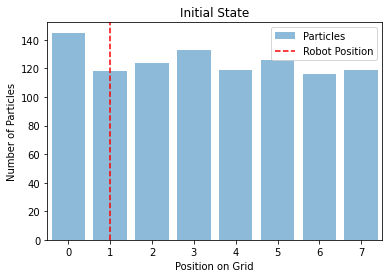

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Define the grid
grid = np.array([1, 1, 0, 0, 1, 1, 1, 0])
grid_length = len(grid)

# Number of particles
N = 1000

# Initialize particles randomly across the grid
particles = np.random.choice(grid_length, N)
weights = np.ones(N) / N

# Set the robot's initial position
robot_pos = 1

# Initialize lists for plotting
positions = []
robot_positions = []

# Plot the initial particle distribution and robot position
plt.figure()
plt.hist(particles, bins=range(grid_length + 1), alpha=0.5, label='Particles', align='left', rwidth=0.8)
plt.axvline(robot_pos, color='r', linestyle='--', label='Robot Position')
plt.xlim(-0.5, grid_length - 0.5)
plt.xticks(range(grid_length))
plt.legend()
plt.title('Initial State')
plt.xlabel('Position on Grid')
plt.ylabel('Number of Particles')
plt.show()

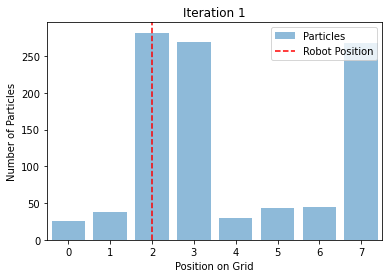

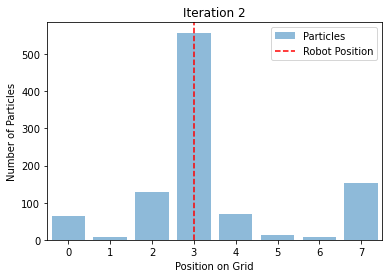

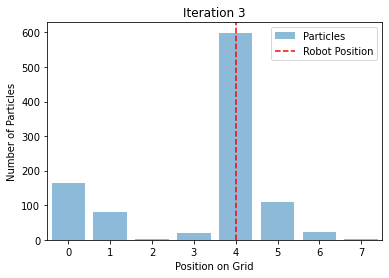

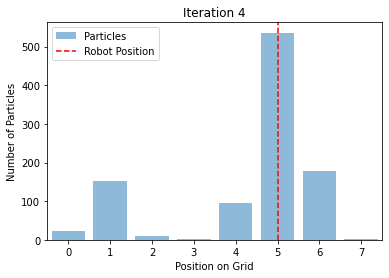

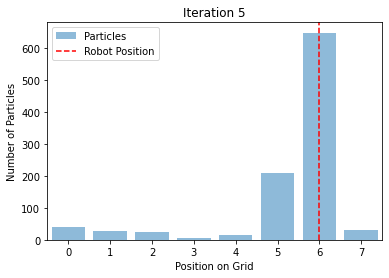

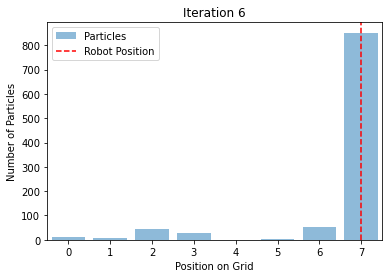

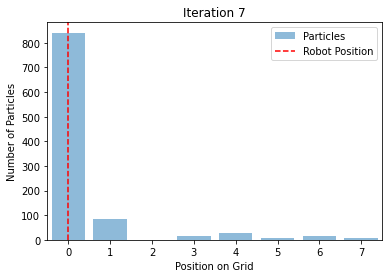

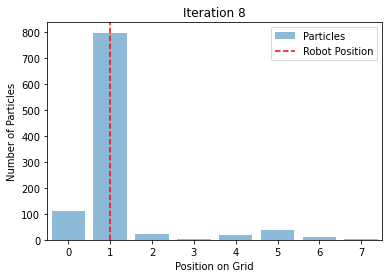

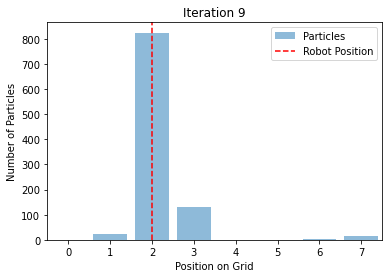

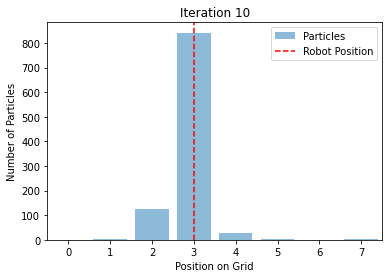

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Define the grid
grid = np.array([1, 1, 0, 0, 1, 1, 1, 0])
grid_length = len(grid)

# Number of particles
N = 1000

# Initialize particles randomly across the grid
particles = np.random.choice(grid_length, N)
weights = np.ones(N) / N

# Set the robot's initial position
robot_pos = 1

# Define number of iterations
num_iterations = 10

# Measurement model probabilities
prob_correct = 0.9
prob_incorrect = 0.1

# For plotting
positions = []
robot_positions = []

for t in range(num_iterations):
    # Move the robot one step to the right
    robot_pos = (robot_pos + 1) % grid_length

    # Move particles similarly to the robot, with some noise
    movement_noise = np.random.choice([-1, 0, 1], N, p=[0.1, 0.8, 0.1])
    particles = (particles + 1 + movement_noise) % grid_length

    # Sensor reading at the robot's true position
    sensor_reading = grid[robot_pos]

    # Update weights based on sensor reading
    weights = np.where(grid[particles] == sensor_reading, prob_correct, prob_incorrect)

    # Normalize weights
    weights += 1.e-300      # Avoid division by zero
    weights /= weights.sum()

    # Resample particles based on weights
    indices = np.random.choice(N, N, p=weights)
    particles = particles[indices]
    weights.fill(1.0 / N)  # Reset weights after resampling

    # Record positions for plotting
    positions.append(particles.copy())
    robot_positions.append(robot_pos)

    # Plot the particles and robot position
    plt.figure()
    plt.hist(particles, bins=range(grid_length + 1), alpha=0.5, label='Particles', align='left', rwidth=0.8)
    plt.axvline(robot_pos, color='r', linestyle='--', label='Robot Position')
    plt.xlim(-0.5, grid_length - 0.5)
    plt.xticks(range(grid_length))
    plt.legend()
    plt.title(f'Iteration {t + 1}')
    plt.xlabel('Position on Grid')
    plt.ylabel('Number of Particles')
    plt.show()


### The additional corrections are presented during the exercise session and all short responses are given in the Quiz_correction.pdf